<html>
    <div>
        <span style="float: left; font-size: 120%; font-variant: small-caps;">
            Université Paul Sabatier
        </span>
        <span style="float: right; font-size: 120%;">
            Analyse de Fourier et théorie du signal
        </span>
    </div><br><br>
    <div align="center" style="font-size: 300%; font-weight: bold;">
        TP1
    </div>
</html>

# Pour commencer...

Récupérer le fichier [`imtools.py`][1] et l'enregistrer au même endroit que le notebook (clic droit sur le lien, puis "enregistrer la cible du lien sous...").

Puis exécuter le code qui suit.

[1]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/imtools.py>

In [1]:
# Chargement de la totalité de la bibliothèque numpy
%pylab inline

# Chargement des fonctions utilitaires pour lire/enregistrer des images
from imtoolsJeff import *

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


Récupérer également les images de travail suivantes, et les enregistrer au même endroit que le notebook:

- [`lena.png`][1]
- [`barbara.png`][2]
- [`mandrill.png`][3]
- [`peppers.png`][4]
- [`io.png`][5]

[1]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/lena.png>
[2]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/barbara.png>
[3]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/mandrill.png>
[4]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/peppers.png>
[5]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/io.png>

Les fonctions fournies dans `imtools` permettent de manipuler des images en niveaux de gris au format PNG. Voici quelques exemples d'utilisation.

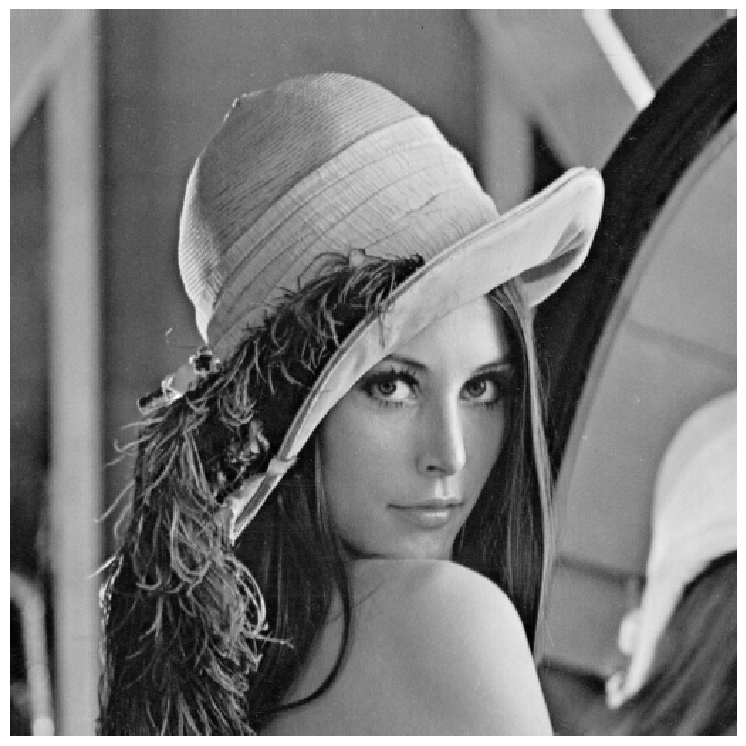

In [2]:
# Chargement et affichage d’une image

i = open_image("lena.png")
display_image(i)

In [3]:
# Enregistrement d'une image de taille 64 x 64

i = zeros((64, 64))
for x in range(64):
    for y in range(64):
        i[x, y] = 3 * x + y
save_image(i, 'test.png')

# Les données ont été sauvegardées dans le fichier test.png

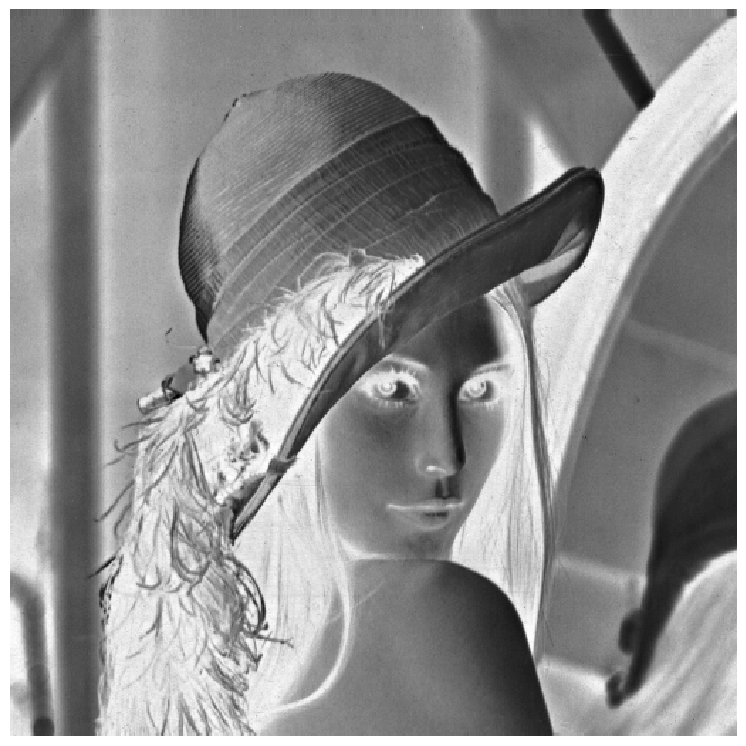

In [4]:
# Affichage d'une image en négatif

i = open_image('lena.png')
j = zeros(i.shape)
for x in range(i.shape[0]):
    for y in range(i.shape[1]):
        j[x, y] = 255 - i[x, y]
display_image(j)

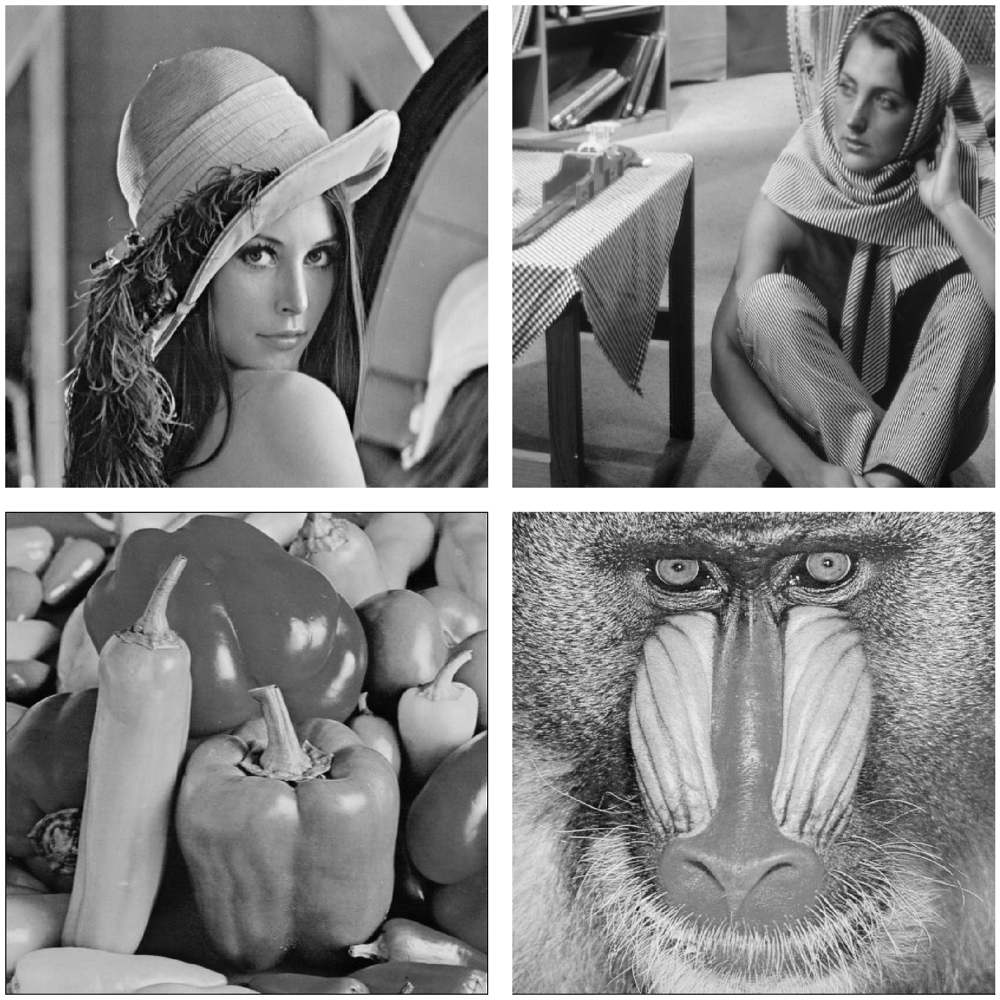

In [5]:
# Affichage de plusieurs images côte-à-côte

i1 = open_image('lena.png')
i2 = open_image('barbara.png')
i3 = open_image('peppers.png')
i4 = open_image('mandrill.png')

display_images([i1, i2, i3, i4])

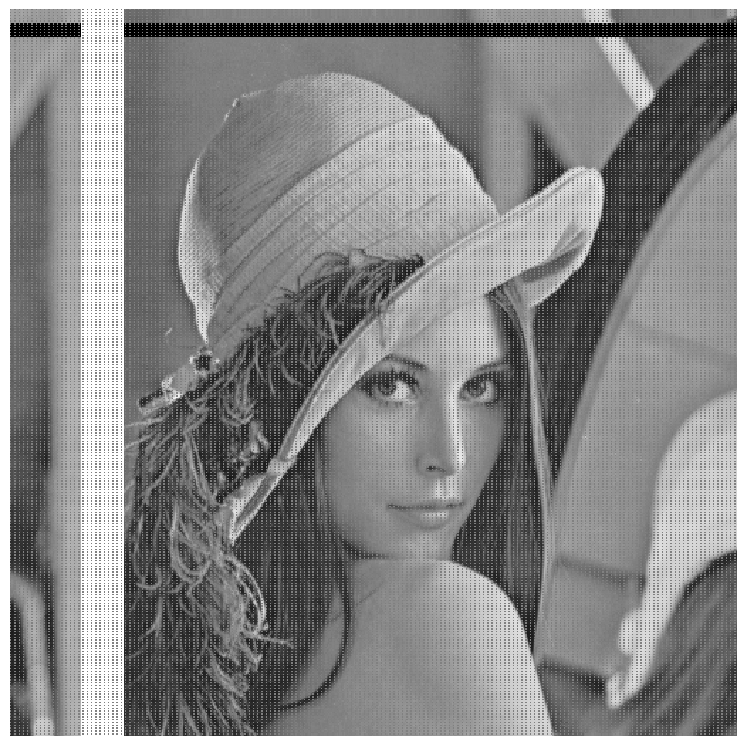

In [6]:
# Accès aux pixels par bloc

i = open_image('lena.png')
#Une bande horizontale noire
i[10:20, :] = 0
#Une bande verticale blanche
i[:, 50:80] = 255
#Accès à un pixel sur six
i[::2, ::3] = 128
display_image(i)

## Exercice 1 – Fenêtrage et échantillonnage

1. Effectuer et afficher le fenêtrage de l'image `lena.png` sur la grille $\{235,\ldots,295\}\times\{240,\ldots,300\}$.

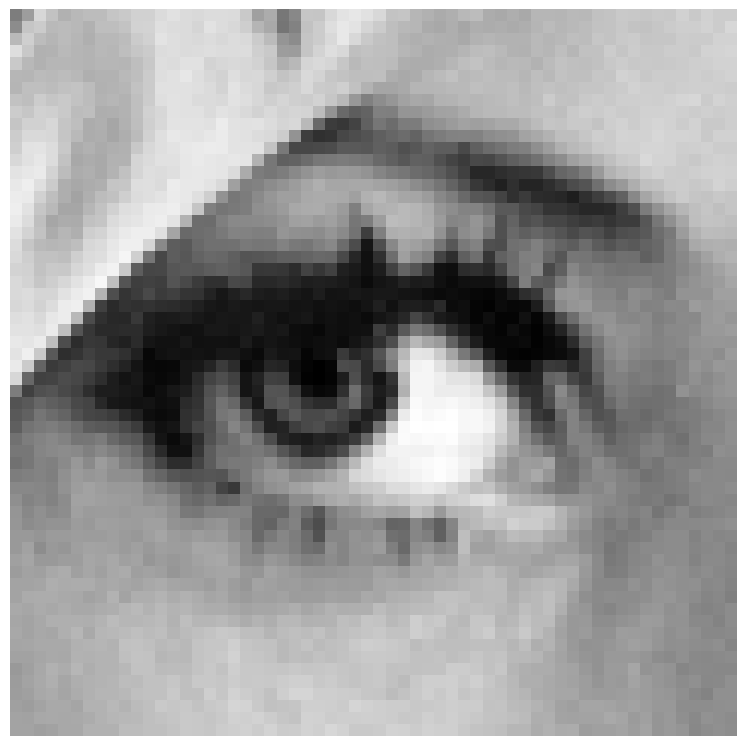

In [7]:
'''n=61
i = zeros((n, n))
k = open_image("lena.png")
for x in range(n):
    for y in range(n):
        i[x, y] = k[x+235,y+240]
#display_image(i)'''

k = open_image("lena.png")
i2 = k[235:295,240:300]
display_image(i2)

2. Effectuer et afficher le sous-échantillonnage de l'image barbara.png aux facteurs $2$, $3$, $4$ et $5$.

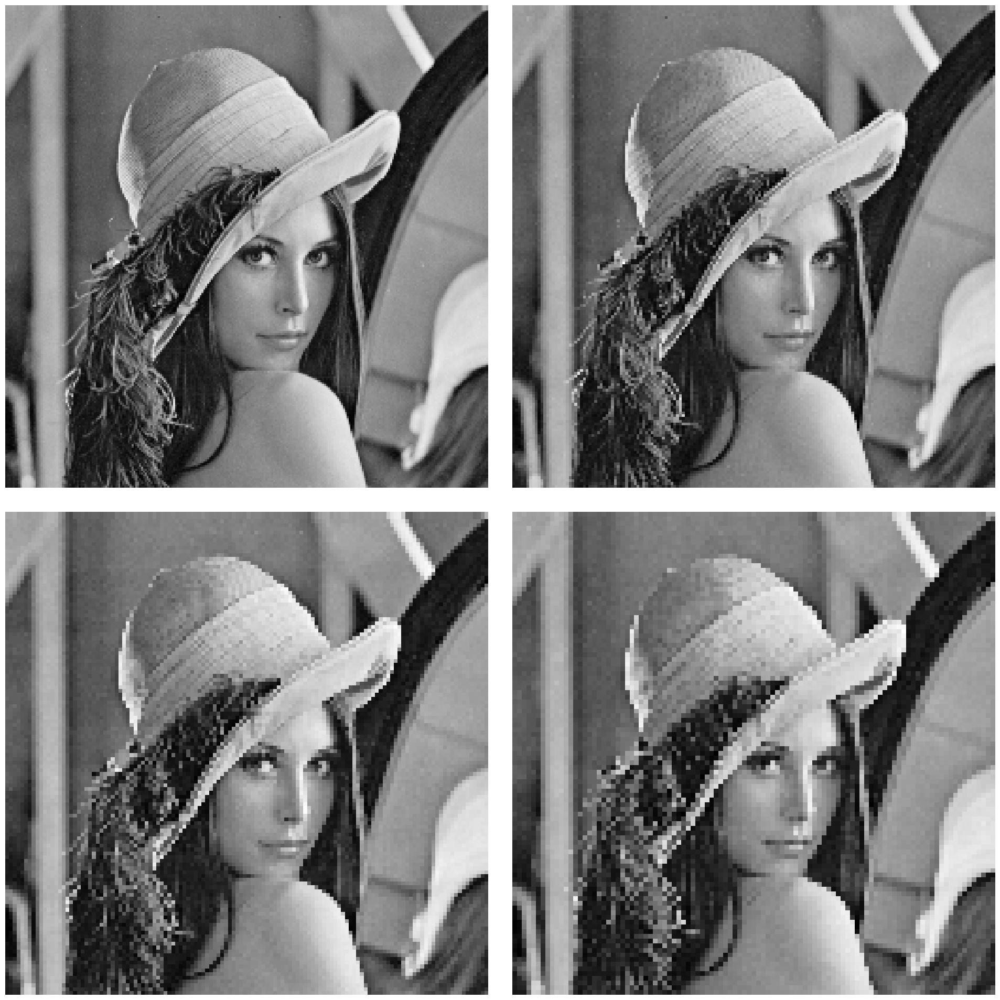

In [8]:
'''k = open_image("barbara.png")
i = zeros(k.shape)
for x in range(k.shape[0]):
    for y in range(k.shape[1]):
        i[x, y] = k[(x//2)*2, (y//2)*2]
#display_image(i)'''

#facteur 2
s = k[::2, ::2]

#facteur 3
s2 = k[::3, ::3]

#facteur 4
s3 = k[::4, ::4]

#facteur 5
s4 = k[::5, ::5]

display_images([s,s2,s3,s4])


3. Décrire qualitativement les résultats obtenu

**<div style=color:red>la quantité de pixel diminue de façon quadratique</div>**

## Exercice 2 – Filtrage

1.  Définir une fonction `moyenne(i, R)` qui prend en paramètres:

    - une image `i`,
    - un entier `R`,

    et qui renvoie l'image obtenue en faisant une convolution par le filtre de moyennage carré de taille $R\times R$. On effectuera la pondération nécessaire pour que le résultat soit à valeurs dans l'intervalle $[0,255]$.

    Pour périodiser l'accès aux pixels d'une image, il est possible d'utiliser l'opérateur "modulo" en Python, qui s'écrit avec le symbole `%`: l'expression

    ```python
a % b
    ```
    
    renvoie le reste de la division euclidienne de $a$ par $b$. Le résultat est un entier compris entre $0$ et $b-1$.

In [9]:
'''def convolution(i,R):
    convolution = zeros(i.shape)
    for x in range(i.shape[0]):
        for y in range (i.shape[1]):
        convolution[x,y] =  moyenne(i,R,x,y)
    display_image(convolution)
    return convolution

def moyenne(i, R,x,y):
    k = zeros(i.shape)
    for m  in range(R):
        #for n in range(R):
        k[x,y] += i[(m+x)%i.shape[0] ,(n+y)%i.shape[1]] * 1/(R**2)
    return k[x,y]'''

def convolution2(i, R):
    temp = zeros(i.shape)
    for x in range(i.shape[0]):
        for y in range(i.shape[1]):
            somme = 0
            for n in range(R): 
                somme += i[x, (y + n) % i.shape[1]]
            temp[x, y] = somme / R

    resultat = zeros(i.shape)
    for x in range(i.shape[0]):
        for y in range(i.shape[1]):
            somme = 0
            for m in range(R):
                somme += temp[(x + m) % i.shape[0], y]
            resultat[x, y] = somme / R
            
    return resultat


2. Réaliser et afficher la convolution de `barbara.png` avec des filtres de tailles $2$, $4$, $6$ et $8$.

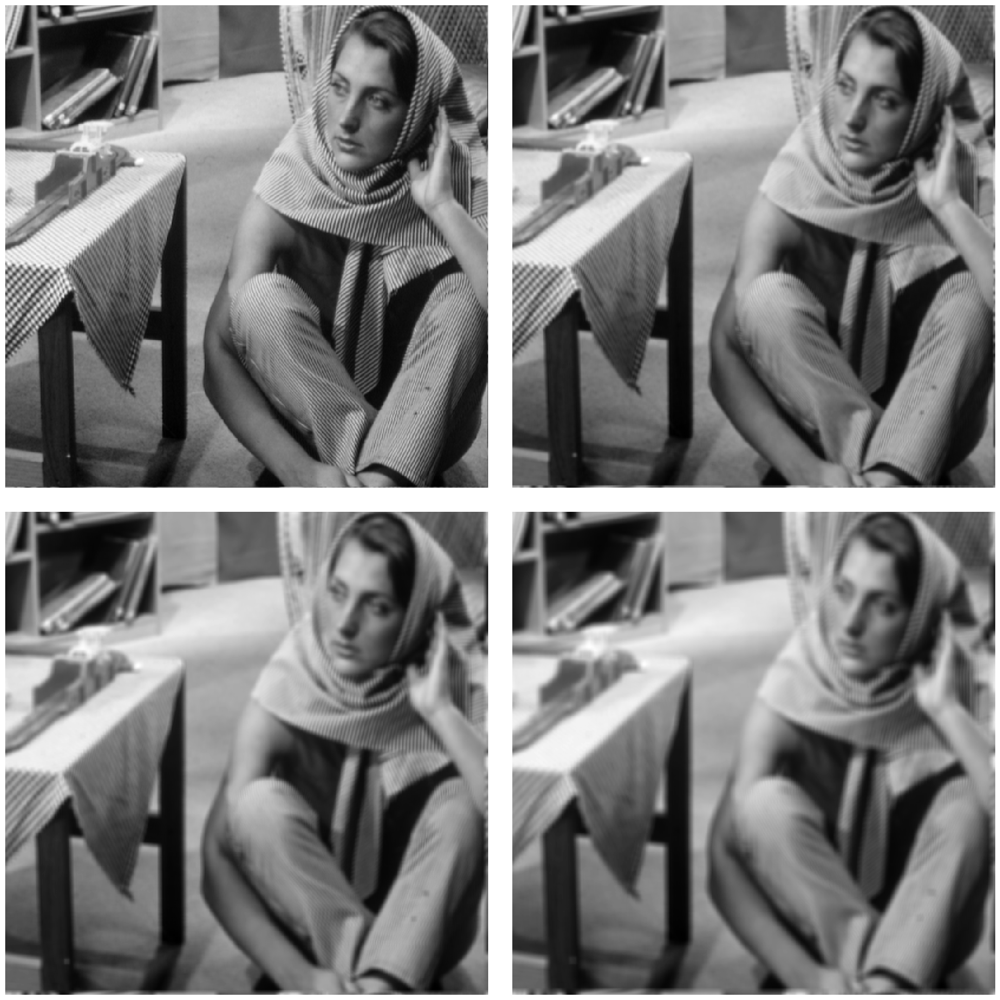

In [10]:
image = open_image("barbara.png")
r2 = convolution2(image, 2)
r4 = convolution2(image, 4)
r6 = convolution2(image, 6)
r8 = convolution2(image, 8)

display_images([r2, r4, r6, r8])


In [11]:
# (merged into cell above)

In [12]:
# (merged into cell above)

In [13]:
# (merged into cell above)

3. Décrire qualitativement les résultats obtenus.

**<div style=color:red>Double-cliquer ici pour écrire une réponse</div>**

## Exercice 3 – Filtrage et échantillonnage

1.   Définir une fonction `echantillonnage2x(i, R)` qui prend en paramètres

    + une image $i$,
    + un entier $R$,
    
    et qui renvoie l'image obtenue après convolution de $i$ par le filtre de moyennage carré de taille $R$, puis sous-échantillonnage d'un facteur $2$.

In [14]:
def echantillonnage2x(i, R):
    convo = convolution2(i, R)
    res = convo[::2, ::2]
    return res


2. Tester sur `barbara.png` avec des fenêtres de tailles $1$, $2$, $4$, $6$ et $8$.

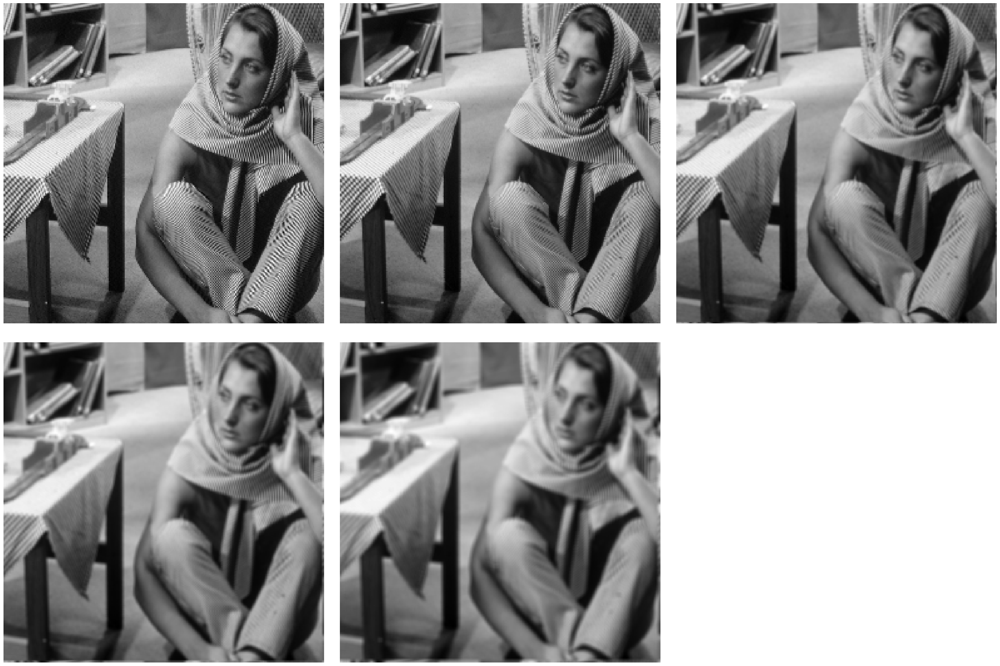

In [15]:
i = open_image("barbara.png")
r1 = echantillonnage2x(i, 1)
r2 = echantillonnage2x(i, 2)
r4 = echantillonnage2x(i, 4)
r6 = echantillonnage2x(i, 6)
r8 = echantillonnage2x(i, 8)

display_images([r1, r2, r4, r6, r8])


In [16]:
# (merged into cell above)

In [17]:
# (merged into cell above)

In [18]:
# (merged into cell above)

In [19]:
# (merged into cell above)

3. Quelle taille $R$ du filtre de moyennage préconisez-vous pour un sous-échantillonnage de facteur 2 ?

   la 2

**<div style=color:red>Double-cliquer ici pour écrire une réponse</div>**

4. Adapter l'expérience des questions précédentes pour déterminer la meilleure taille du filtre de moyennage pour un sous-échantillonnage de facteur 3.

In [20]:
def echantillonnage3x(i, R):
    convo = convolution2(i, R)
    res = convo[::3, ::3]
    return res


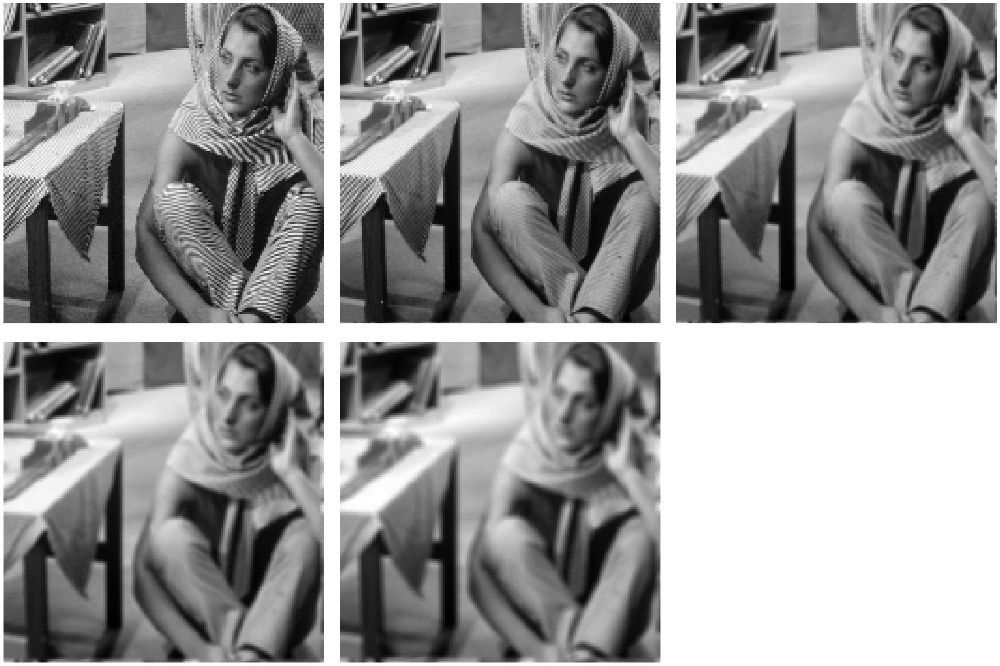

In [21]:
i = open_image("barbara.png")
r1 = echantillonnage3x(i, 1)
r3 = echantillonnage3x(i, 3)
r6 = echantillonnage3x(i, 6)
r9 = echantillonnage3x(i, 9)
r12 = echantillonnage3x(i, 12)

display_images([r1, r3, r6, r9, r12])


In [22]:
# (merged into cell above)

In [23]:
# (merged into cell above)

In [24]:
# (merged into cell above)

In [25]:
# (merged into cell above)

In [26]:
# (merged into cell above)

In [27]:
# (merged into cell above)

## Exercice 4 – Bruit

La fonction

```python
random.normal(0, sigma, size=(N, N))
```

génère un bruit gaussien, centré en zéro et d'écart-type $\sigma$ sous forme d’une image de taille $N\times N$.

1.   Créer une fonction `bruitage(i, sigma)` qui prend en paramètres:

    - une image $i$,
    - un réel $\sigma$,

    et qui renvoie l'image obtenue après ajout d'un bruit gaussien d'écart-type $\sigma$.

In [28]:

def bruitage(image, sigma):
    bruit = np.random.normal(0, sigma, image.shape)
    
    image_bruitee = image + bruit
    
    image_bruitee = np.clip(image_bruitee, 0, 255)
  
    return image_bruitee

2. Visualiser l'effet du bruit sur `barbara.png` pour des valeurs d'écart-type de $2$, $5$, $10$, $20$, $40$, $80$ et $160$.

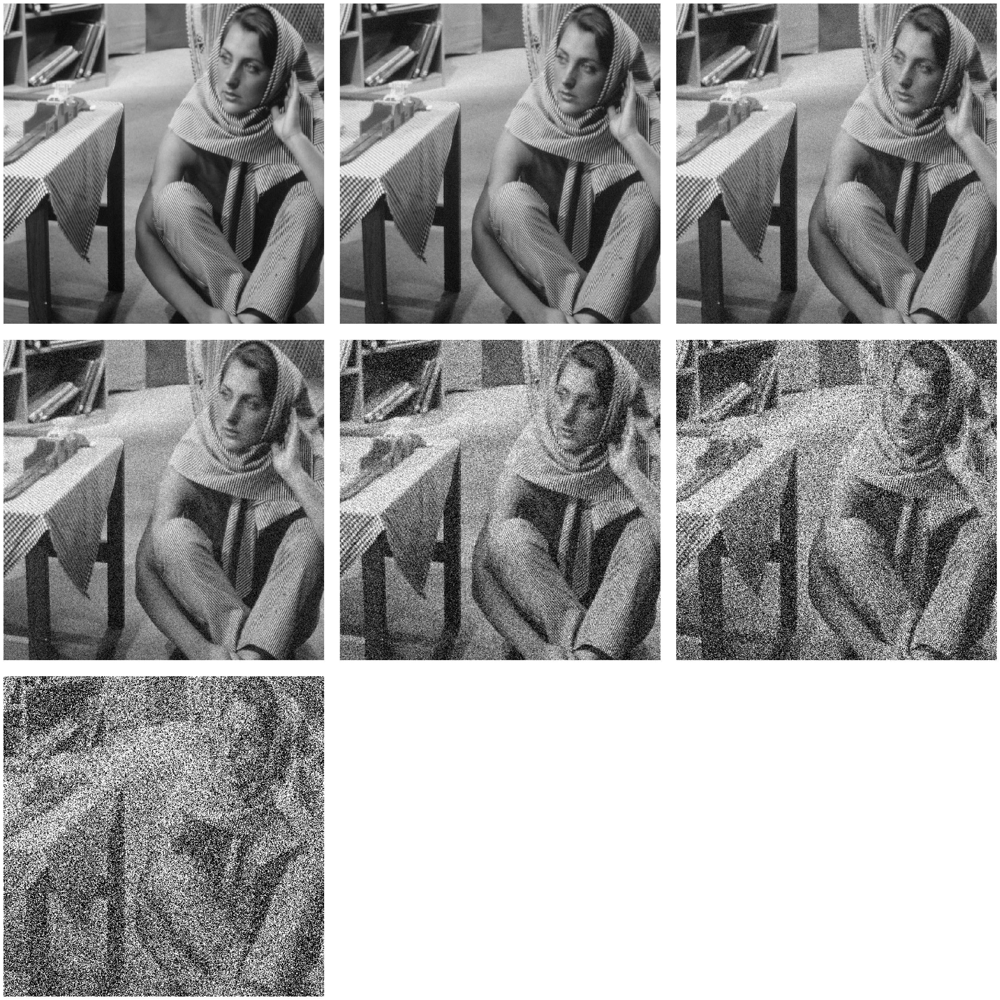

In [29]:
i = open_image("barbara.png")
i1 = bruitage(i, 2)
i2 = bruitage(i, 5)
i3 = bruitage(i, 10)
i4 = bruitage(i, 20)
i5 = bruitage(i, 40)
i6 = bruitage(i, 80)
i7 = bruitage(i, 160)

display_images([i1,i2,i3,i4,i5,i6,i7])



3. Décrire qualitativement les résultats obtenus.

**<div style=color:red>Double-cliquer ici pour écrire une réponse</div>**

## Exercice 5 – Quantification à pas constant

Pour l'affichage des images quantifiées, on utilisera les fonctions `display_image` et `display_images` avec les paramètres supplémentaires `vmin=0` et `vmax=255`:

```python
display_image(image, vmin = 0, vmax = 255)
```

ou

```python
display_images(images, vmin = 0, vmax = 255)
```

Ceux-ci garantissent que la valeur $0$ sera affichée comme du noir et $255$ comme du blanc. Dans le cas contraire, Python procède à un ajustement automatique avec les valeurs minimales et maximales de l’image, ce qui n'est pas souhaitable ici.

1.  Écrire une fonction `quantify1(i, Q)` qui prend en paramètres:

    - une image $i$,
    - un entier $Q$,

    et qui renvoie l'image $i$ après requantification sur $Q$ niveaux de gris.

    On pourra utiliser l'expression

    ```python
int(round(z))
    ```

    qui, lorsque $z$ est un nombre flottant, renvoie l'entier le plus proche de $z$.

    Où si l'on préfère , on pourra utiliser l'expression

    ```python
np.round(tableau).astype(int)
    ```

    qui effectue le même calcul lorsqu'on travaille avec un tableau.

In [30]:
def quantify(i, q):
    pas = 256/q
    i_quant = np.floor((i/pas)*q)
    return i_quant

2. Quantifier et visualiser les images `barbara.png` et `io.png` aux niveaux $2$, $3$, $4$, $6$, $8$, $10$ et $20$.

Barbara - quantification à pas constant
Io - quantification à pas constant


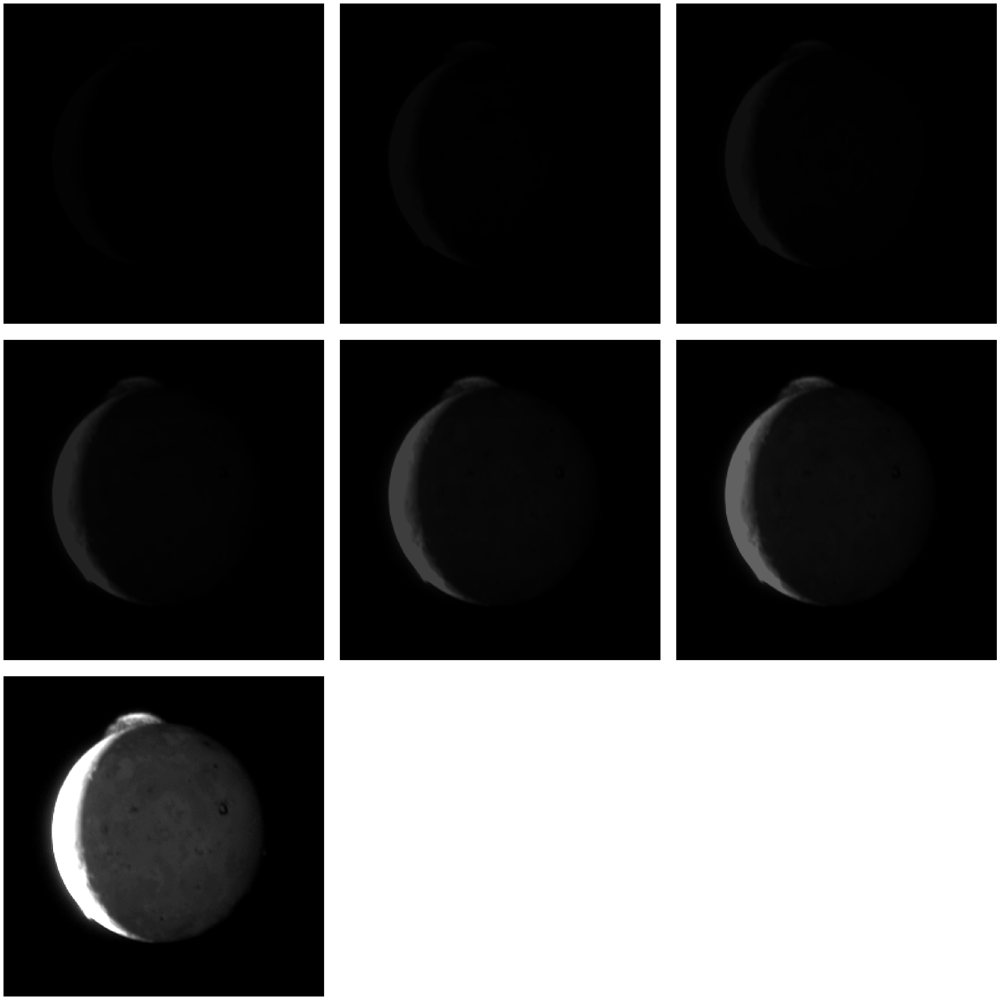

In [31]:
i = open_image("barbara.png")
k = open_image("io.png")

niveaux = [2, 3, 4, 6, 8, 10, 20]
barbara_quant = [quantify(i, q) for q in niveaux]
io_quant = [quantify(k, q) for q in niveaux]

print("Barbara - quantification à pas constant")
display_images(barbara_quant, vmin=0, vmax=255)

print("Io - quantification à pas constant")
display_images(io_quant, vmin=0, vmax=255)


3. Décrire qualitativement les résultats obtenus.

**<div style=color:red>Double-cliquer ici pour écrire une réponse</div>**

## Exercice 6 – Égalisation d'histogramme

La fonction

```python
plt.plot(X, Y)
```

où $X$ et $Y$ sont deux tableaux unidimensionnels, affiche le graphe de $Y$ (en ordonnée) en fonction de $X$ (en abscisse).

Si l'on ne donne pas les abscisses,

```python
plt.plot(Y)
```

effectue la même opération en générant automatiquement des abscisses.

1. Écrire une fonction `histogramme_cumule(i)` qui renvoie l'histogramme cumulé normalisé d'une image $i$ sous la forme d'un tableau de $256$ flottants.

In [32]:
def histogramme_cumule(i):
    h = np.zeros(256)
    flat = i.flatten().astype(int)
    for v in flat:
        h[np.clip(v, 0, 255)] += 1
    h_cum = np.cumsum(h)
    h_cum = h_cum / h_cum[-1]  # normalisation
    return h_cum


2. Représenter les histogrammes des images `lena.png`, `barbara.png` et `io.png`.

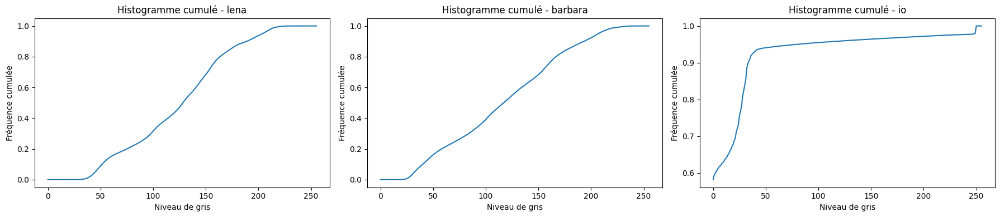

In [33]:
lena = open_image("lena.png")
barbara = open_image("barbara.png")
io_img = open_image("io.png")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, img, name in zip(axes, [lena, barbara, io_img], ["lena", "barbara", "io"]):
    h = histogramme_cumule(img)
    ax.plot(h)
    ax.set_title(f"Histogramme cumulé - {name}")
    ax.set_xlabel("Niveau de gris")
    ax.set_ylabel("Fréquence cumulée")
plt.tight_layout()
plt.show()


3. Implémenter l'algorithme d'égalisation d'histogramme vu en TD sous la forme d’une fonction `egalise(i)`.

In [34]:
def egalise(i):
    h_cum = histogramme_cumule(i)
    lut = (h_cum * 255).astype(np.float32)
    i_eq = lut[np.clip(i.flatten().astype(int), 0, 255)].reshape(i.shape)
    return i_eq


4. Tester avec les images mentionnées plus haut et décrire qualitativement les résultats obtenus.

Avant / Après égalisation - Lena, Barbara, Io


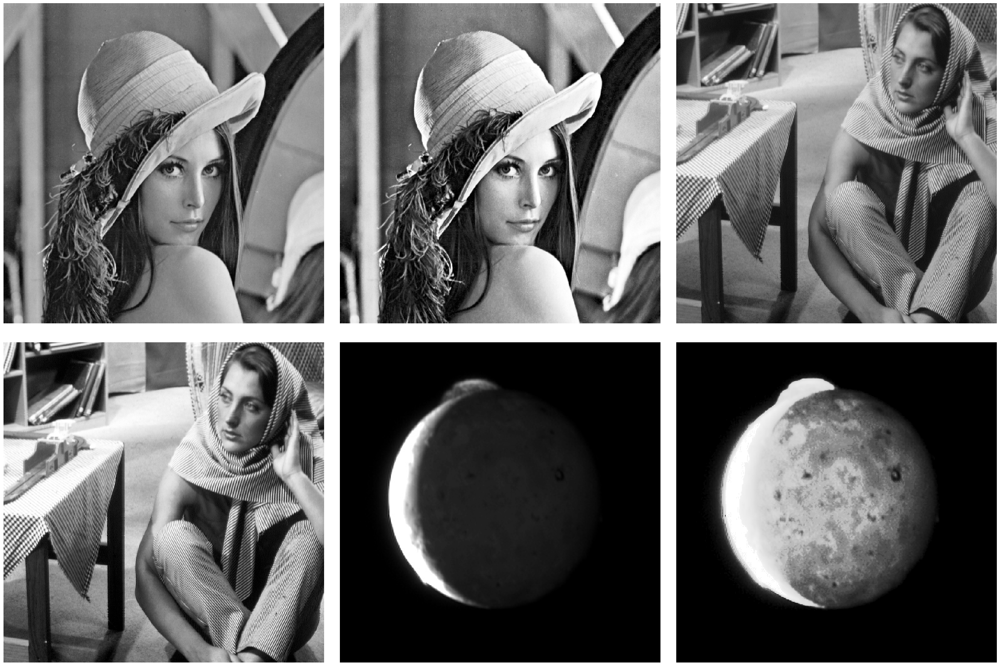

In [35]:
lena = open_image("lena.png")
barbara = open_image("barbara.png")
io_img = open_image("io.png")

lena_eq = egalise(lena)
barbara_eq = egalise(barbara)
io_eq = egalise(io_img)

print("Avant / Après égalisation - Lena, Barbara, Io")
display_images([lena, lena_eq, barbara, barbara_eq, io_img, io_eq], lines=2, columns=3)


## Exercice 7 – Quantification à pas variable

1. Écrire une fonction `quantify2(i, Q)` qui effectue une quantification sur $Q$ niveaux en découpant l'histogramme de l'image en $Q$ classes d’effectif comparables, et en attribuant aux pixels de chaque classe sa valeur moyenne.

In [36]:
def quantify2(i, Q):
    flat = i.flatten()
    sorted_pixels = np.sort(flat)
    N = len(flat)
    result = np.zeros_like(flat)
    
    for q in range(Q):
        idx_start = int(q * N / Q)
        idx_end = int((q + 1) * N / Q)
        # seuils en valeur de pixel
        v_low = sorted_pixels[idx_start]
        v_high = sorted_pixels[idx_end - 1] if idx_end < N else sorted_pixels[-1]
        
        # masque des pixels dans cette classe
        mask = (i.flatten() >= v_low) & (i.flatten() <= v_high)
        if np.any(mask):
            mean_val = np.mean(flat[mask])
            result[mask] = mean_val
    
    return result.reshape(i.shape)


2. Quantifier avec cette méthode et visualiser les images `barbara.png` et `io.png` aux niveaux $2$, $3$, $4$, $6$, $8$, $10$ et $20$.

In [ ]:
i = open_image("barbara.png")
k = open_image("io.png")

niveaux = [2, 3, 4, 6, 8, 10, 20]
barbara_q2 = [quantify2(i, q) for q in niveaux]
io_q2 = [quantify2(k, q) for q in niveaux]

print("Barbara - quantification à pas variable")
display_images(barbara_q2, vmin=0, vmax=255)

print("Io - quantification à pas variable")
display_images(io_q2, vmin=0, vmax=255)


Barbara - quantification à pas variable
Io - quantification à pas variable


3.   Comparer le bruit de quantification de cette méthode avec celle de l'exercice 5.

    On pourra utiliser la fonction `np.var(i)` qui, si $i$ est une image, renvoie la variance (statistique) des valeurs de ses pixels.

In [ ]:
i = open_image("barbara.png")
k = open_image("io.png")

niveaux = [2, 3, 4, 6, 8, 10, 20]

print("Bruit de quantification (variance de la différence) - Barbara")
print(f"{'Niveaux':>8} | {'Exo5 (pas constant)':>20} | {'Exo7 (pas variable)':>20}")
print("-" * 55)
for q in niveaux:
    q1 = quantify(i, q)
    q2 = quantify2(i, q)
    var1 = np.var(i - q1)
    var2 = np.var(i - q2)
    print(f"{q:>8} | {var1:>20.2f} | {var2:>20.2f}")

print()
print("Bruit de quantification (variance de la différence) - Io")
print(f"{'Niveaux':>8} | {'Exo5 (pas constant)':>20} | {'Exo7 (pas variable)':>20}")
print("-" * 55)
for q in niveaux:
    q1 = quantify(k, q)
    q2 = quantify2(k, q)
    var1 = np.var(k - q1)
    var2 = np.var(k - q2)
    print(f"{q:>8} | {var1:>20.2f} | {var2:>20.2f}")


4. Décrire qualitativement les résultats obtenus.

**<div style=color:red>Double-cliquer ici pour écrire une réponse</div>**